# Machine Learning - Apprentissage Supervisé
## Classification Multiclasses (Dataset Iris)

### Étapes du pipeline :
1. **Chargement et exploration des données**
2. **Préparation et transformation des données** (Train/Test Split & Standardisation)
3. **Entraînement du modèle** (Régression Logistique)
4. **Évaluation du modèle** (Accuracy & Rapport de classification)
5. **Prédictions sur de nouvelles données**

### 1. Importation des bibliothèques et chargement des données

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

data = pd.read_csv('Iris.csv')
data.head()

In [7]:
# statistiques
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,150.0,75.500000,43.445368,1.0,38.25,75.50,112.75,150.0
SepalLengthCm,150.0,5.843333,0.828066,4.3,5.10,5.80,6.40,7.9
SepalWidthCm,150.0,3.054000,0.433594,2.0,2.80,3.00,3.30,4.4
PetalLengthCm,150.0,3.758667,1.764420,1.0,1.60,4.35,5.10,6.9
PetalWidthCm,150.0,1.198667,0.763161,0.1,0.30,1.30,1.80,2.5


### graphique

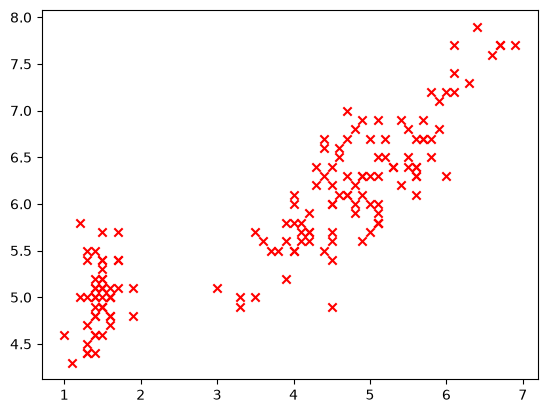

In [8]:
plt.scatter(data['PetalLengthCm'], data['SepalLengthCm'], color='red', marker='x')

### 2. Préparation et transformation des données

In [9]:
# 1. Séparation des caractéristiques (X) et de la cible (y)
X = data.drop(columns=['Id', 'Species'])
y = data['Species']



# 2. Découpage Train / Test (80% entraînement, 20% test)
# stratify=y garantit les mêmes proportions de chaque espèce dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardisation (moyenne = 0, écart-type = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 3. Entraînement du modèle

In [10]:
# Création du modèle de régression logistique
model = LogisticRegression(max_iter=200)

# Entraînement sur le jeu d'entraînement uniquement
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

### 4. Évaluation du modèle

In [11]:
# Prédiction sur les données de test (données jamais vues)
y_pred = model.predict(X_test_scaled)

# Calcul de la précision
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy:.2%}")

# Rapport détaillé (Précision, Rappel, F1-Score par espèce)
print("\nRapport de classification :\n", classification_report(y_test, y_pred))

Accuracy : 93.33%

Rapport de classification :
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



### 5. Prédiction sur de nouvelles données

In [12]:
# Exemple de 3 nouvelles fleurs avec les 4 caractéristiques mesurées :
# Fleur 1 : petits pétales (Iris-setosa attendue)
# Fleur 2 : pétales moyens (Iris-versicolor attendue)
# Fleur 3 : grands pétales (Iris-virginica attendue)
new_data = pd.DataFrame([
    [5.1, 3.5, 1.4, 0.2],
    [6.0, 2.7, 4.0, 1.2],
    [6.9, 3.1, 5.4, 2.1]
], columns=X.columns)

# Standardisation avec le scaler déjà entraîné
new_data_scaled = scaler.transform(new_data)

# Prédiction des espèces
predictions = model.predict(new_data_scaled)

print("Prédictions pour les nouvelles fleurs :", predictions)

Prédictions pour les nouvelles fleurs : ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


## Bonus: voir les differentes classes que le modele a appris

In [13]:
print(model.classes_)

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
